# Acute oddball responses and retained learning in a developmental auditory circuit

During early exposure, each rare tone evoked more layer 4 firing than a frequent tone. When both tones were later tested in isolation, the formerly frequent tone had gained more response. How can the same circuit give these two answers?

This notebook follows one tone from input spikes to synaptic release, cortical firing, and a held-out test of learning. It compares two developmental parameter sets, checks numerical accuracy, and asks whether letting the subplate relay learn would reverse the early preference.

In mice, Mehra and colleagues compared oddball selectivity during development and measured adult cortical responses after exposure. Here the sounds are two tone classes, and training and testing use the same developmental parameters. The first experiment motivates the model; the second identifies a biological outcome beyond the model's observation window. [Mehra et al., 2022](https://doi.org/10.1523/JNEUROSCI.0431-21.2021)

**Running the notebook.** Extract the full checkpoint and open this notebook in the `project/` directory. Start a fresh Python kernel and run all cells. Short reference simulations execute locally. Longer experiments are represented by checked measurements in the sibling stage directories. The final section links each analysis to its regeneration commands.

In [1]:
from pathlib import Path
from dataclasses import asdict
from io import BytesIO
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import Image, display

cwd = Path.cwd()
project = cwd if (cwd / "auditory/kernel.c").is_file() else cwd / "project"
root = project.parent
assert (root / "stage6/estimates.csv").is_file(), "Extract the full checkpoint first."
sys.path.insert(0, str(project))
from auditory import Config, make_stimulus, release_step, simulate
from run_experiments import event_table

def read(path):
    return pd.read_csv(root / path)

def summary(values):
    values = np.asarray(values, dtype=float)
    assert values.ndim == 1 and len(values) > 1 and np.isfinite(values).all()
    mean = values.mean()
    half = t.ppf(.975, len(values)-1) * values.std(ddof=1) / np.sqrt(len(values))
    return np.array([mean, mean-half, mean+half])

def show_intervals(rows, unit):
    frame = pd.DataFrame(rows, columns=["Measurement", "Regime", "Seeds", "Mean", "95% lower", "95% upper"])
    display(frame.rename(columns={"Mean": f"Mean ({unit})"}).round(5).set_index(["Measurement","Regime"]))

def show_plot(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=135, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

early, late = (Config.for_regime(age) for age in ("early","late"))
RESULTS = project / "results"
pd.set_option("display.precision", 5)

## 1. What changes with development?

Forty thalamic afferents, four per frequency class, drive 40 subplate neurons (SP) and project directly to 40 layer 4 neurons (L4). SP excites L4 and also excites 10 inhibitory interneurons that suppress L4. The two excitatory routes converge on individual L4 cells. Nearby frequencies share recipients through locally weighted connectivity on a tuning ring. This design keeps the physical tone identity available after the first synapse.

The early and late regimes differ in three parameters. The table reports the incoming conductance scales before short-term release and learned efficacy are applied. The early regime has stronger SP drive to L4 and slower resource recovery. The late regime has stronger direct thalamic drive. The same seed draws the same structural realization and thresholds in both regimes. These parameters represent developmental hypotheses. The anatomical relay itself has experimental support. [Zhao, Kao & Kanold, 2009](https://doi.org/10.1523/JNEUROSCI.4471-09.2009)

,Early,Late
SP → L4 conductance scale,8.0,3.2
Thalamus → L4 conductance scale,6.4,16.0
Resource recovery (ms),650.0,350.0
Released fraction U,0.35,0.35
Integration step (ms),0.5,0.5


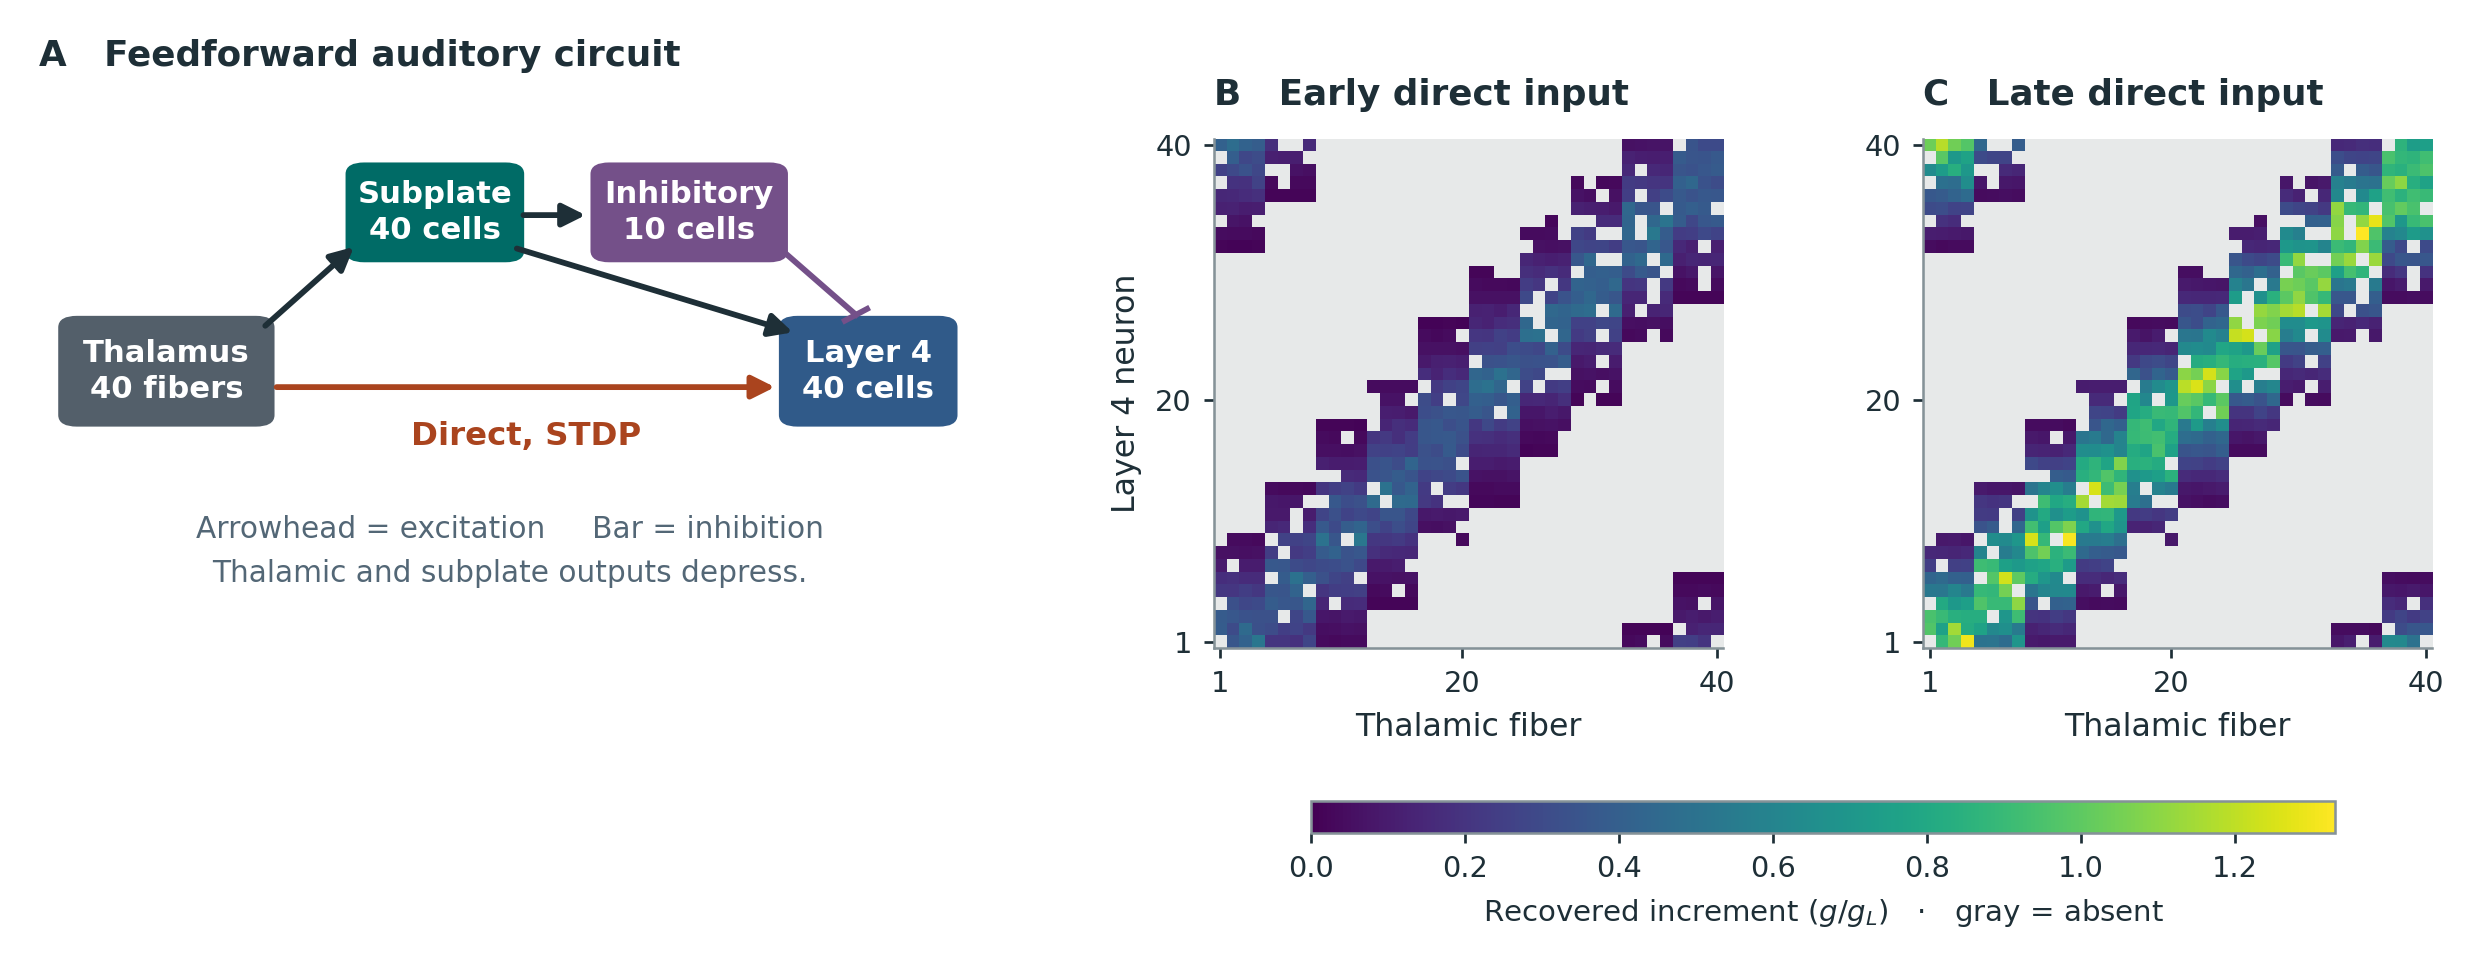

In [2]:
params = pd.DataFrame({"Early": asdict(early), "Late": asdict(late)})
display(params.loc[["sp_scale","direct_scale","tau_rec","utilization","dt"]].rename(index={
    "sp_scale":"SP → L4 conductance scale", "direct_scale":"Thalamus → L4 conductance scale",
    "tau_rec":"Resource recovery (ms)", "utilization":"Released fraction U", "dt":"Integration step (ms)"}))
display(Image(filename=str(project / "figures/01_circuit.png"), width=850))

## 2. From an input spike to a learned efficacy

With time in milliseconds, voltage in mV and conductances relative to leak, a neuron between spikes obeys

$$
\tau_m\dot V=(E_L-V)+g_E(E_E-V)+g_I(E_I-V),\qquad
\dot g_E=-g_E/5,\quad \dot g_I=-g_I/10.
$$

The reversal potentials are $E_L=-65$, $E_E=0$ and $E_I=-80$ mV. The membrane time constant is 20 ms for SP and L4 and 12 ms for interneurons. On an interval of length $h$, the solver evaluates the decaying conductances at its midpoint. With $a=1+\bar g_E+\bar g_I$ and $V_\infty=(E_L+\bar g_E E_E+\bar g_I E_I)/a$, it advances voltage by

$$
V_{k+1}=V_\infty+(V_k-V_\infty)\exp(-ah/\tau_m).
$$

The exponential update is exact for the frozen conductances. Threshold detection occurs at the right boundary. A spike resets voltage to −65 mV and starts a 2 ms refractory interval. Cortical spikes arrive after 1 ms. External arrivals are assigned to the first represented boundary at or after their timestamp.

**Short-term depression.** Immediately before a spike, a source has available fraction $x^-$. Its release is $Ux^-$, leaving $x^+=(1-U)x^-$. After a gap $T$, the fraction recovers to $1-(1-x^+)e^{-T/\tau_{\mathrm{rec}}}$. Both branches from each thalamic or SP source share its resource. A frequent sequence can therefore reduce a later target's response before any long-term efficacy changes. The cell below checks periodic steady release against the C kernel. [Tsodyks & Markram, 1997](https://doi.org/10.1073/pnas.94.2.719)

In [3]:
U, period, tau = early.utilization, 30.0, early.tau_rec
x = 1.0
q = np.exp(-period / tau)
for _ in range(400):
    x, released = release_step(x, 1, U, period, tau)
expected = U * (1-q) / (1-(1-U)*q)
np.testing.assert_allclose(released, expected, rtol=1e-12)
print(f"First fully recovered release = {U:.4f}; steady release = {released:.6f} of the pool.")

First fully recovered release = 0.3500; steady release = 0.041619 of the pool.


**Long-term learning.** In the baseline, spike-timing-dependent plasticity (STDP) acts on each existing direct thalamus→L4 contact. At a grid boundary, let $n,m$ count current pre- and postsynaptic events. Let $a,b$ be their respective traces, decayed with a 20 ms time constant and containing only previous events. The normalized efficacy changes by

$$
w^+=\mathrm{clip}_{[0,1]}\bigl(w+0.004(1-w)am-0.0044wbn\bigr).
$$

Traces receive $n,m$ after this update. A pre-before-post pair can potentiate and a post-before-pre pair can depress. An isolated zero-lag pair contributes zero. The 90 frequent-tone opportunities and 10 rare-tone opportunities accumulate different histories of both signs. A larger response per rare tone alone does not determine the net weight change.

After 100 presentations, the rare-minus-frequent change in direct efficacy averaged −0.01483 early and +0.00057 late. The early direct pathway preferentially strengthened the frequent tone. The held-out tests in Section 5 ask whether that efficacy difference changes firing.

## 3. Does an identical tone elicit more spikes when it is rare?

A 50 ms burst activates four afferents at 50 Hz each over 0.2 Hz background per afferent. Onsets are 300 ms apart. A 100-tone oddball stream contains exactly ten rare presentations. A counterbalanced stream exchanges physical tones 0 and 5. Network wiring and afferent drive are generated from separate random streams indexed by the same experimental seed.

For each presentation, subtract the population spike count in the 100 ms before onset from the count in the first 100 ms after onset. Divide by 40 L4 cells and 0.1 s for Hz/cell. The next cell reruns one seed with both role assignments and both developmental parameter sets. It checks the live counts against the archived run estimates.

In [4]:
seed = 1001
run_table = pd.read_csv(RESULTS / "run_metrics.csv")
design = {}
for age, cfg in (("early", early), ("late", late)):
    sample = make_stimulus(cfg, seed=seed, n_tokens=100)
    design[age] = sample
np.testing.assert_array_equal(design["early"].input_times, design["late"].input_times)
np.testing.assert_array_equal(design["early"].input_cells, design["late"].input_cells)

replay = []
for age, cfg in (("early", early), ("late", late)):
    for swap in (False, True):
        res = simulate(cfg, seed=seed, n_tokens=100, swap=swap)
        trial = event_table(res)
        rate = (trial.l4_post - trial.l4_pre) / (40 * .1)
        role_rate = rate.groupby(trial.role).mean()
        gap = role_rate["dev"] - role_rate["std"]
        saved = run_table.query("condition=='intact' and epoch=='all' and regime==@age and seed==@seed and swap==@swap")
        np.testing.assert_allclose(gap, saved.l4_dev_minus_std_hz.iloc[0], atol=1e-7)
        replay.append((age, res.deviant, role_rate["std"], role_rate["dev"], gap))
display(pd.DataFrame(replay, columns=["stage","rare tone","frequent Hz/cell","rare Hz/cell","difference"]))

,stage,rare tone,frequent Hz/cell,rare Hz/cell,difference
0,early,5,1.92500,3.925,2.00000
1,early,0,1.89444,3.950,2.05556
2,late,5,2.58889,2.850,0.26111
3,late,0,2.35556,3.175,0.81944


**Across independent seeds.** Compute the rare and frequent means separately within each assignment, subtract frequent from rare, and average the two assignments within each seed. The interval is the seed mean plus or minus the 97.5th percentile of Student's t times the seed standard error. Cells, tone presentations, assignments, and probe bursts contribute to each measurement. The independent sample size here is eight.

In [5]:
tokens = pd.read_csv(RESULTS / "token_counts.csv.gz").query("condition == 'intact'").copy()
tokens["response"] = (tokens.l4_post - tokens.l4_pre) / (40*.1)
role = tokens.groupby(["regime","seed","swap","role"]).response.mean().unstack()
acute = (role.dev-role["std"]).groupby(["regime","seed"]).mean()
reference = read("stage2/primary_estimates.csv").query("metric=='l4_dev_minus_std_hz'").set_index("regime")
rows = []
for age in ("early","late"):
    values = acute.loc[age]
    estimate = summary(values)
    np.testing.assert_allclose(estimate, reference.loc[age,["mean","lo","hi"]].to_numpy(dtype=float))
    rows.append(("Rare − frequent", age, len(values), *estimate))
show_intervals(rows, "Hz/cell")

Seeds  Mean (Hz/cell)  95% lower  95% upper
Measurement     Regime                                             
Rare − frequent early       8         1.50312    1.15810    1.84815
                late        8         0.46250    0.30534    0.61966

The acute rare-tone advantage was larger early (+1.503 Hz/cell) than late (+0.463 Hz/cell). The ordinary oddball comparison changes both a target's frequency and the history of surrounding tones. A many-standards control holds the target's frequency, identity, timing, and afferent burst fixed while changing the other sounds. This allows a more specific question about context. [Mill et al., 2011](https://doi.org/10.1371/journal.pcbi.1002117)

## 4. How much of the early context effect comes from the previous sound?

For each rare target, Stage 3 crossed the history before the preceding sound with the identity of that last sound. O denotes an oddball source and M a many-standards source. For example, OM uses an earlier oddball sequence followed by the many-standards predecessor. Averaging the two within-history predecessor differences and the two within-predecessor earlier-history differences partitions the full OO−MM contrast under this convention. Their interaction makes the partition convention-dependent.

In [6]:
cells = read("stage3/seed_cells.csv").pivot(index=["site","seed"],columns=["history","predecessor"],values="l4_hz")
oo, om, mo, mm = (cells[key] for key in [("O","O"),("O","M"),("M","O"),("M","M")])
parts = {"total": oo-mm, "predecessor": ((oo-om)+(mo-mm))/2, "earlier": ((oo-mo)+(om-mm))/2}
np.testing.assert_allclose(parts["predecessor"] + parts["earlier"], parts["total"], atol=1e-12)
saved = read("stage3/estimates.csv").query("metric=='l4_hz'").set_index(["site","contrast"])
rows = []
for site, label in [("intact","Both sites depress"),("thalamus_only","Thalamus only")]:
    for contrast, series in parts.items():
        vals = series.loc[site]
        est = summary(vals)
        np.testing.assert_allclose(est,saved.loc[(site,contrast),["mean","lo","hi"]].to_numpy(dtype=float),atol=1e-12)
        rows.append((f"{label} · {contrast}","early",len(vals),*est))
show_intervals(rows, "Hz/cell")

,,Seeds,Mean (Hz/cell),95% lower,95% upper
Measurement,Regime,,,,
Both sites depress · total,early,8,0.27344,0.15661,0.39027
Both sites depress · predecessor,early,8,0.10234,0.05775,0.14694
Both sites depress · earlier,early,8,0.17109,0.08216,0.26003
Thalamus only · total,early,8,0.00625,-0.02223,0.03473
Thalamus only · predecessor,early,8,0.00000,-0.01368,0.01368
Thalamus only · earlier,early,8,0.00625,-0.01051,0.02301


The intact same-target difference was +0.273 Hz/cell. Changing the last sound accounted for +0.102 Hz/cell and changing the earlier history accounted for +0.171 Hz/cell. With depression confined to thalamic outputs, the full contrast was +0.006 Hz/cell and its interval included zero. The intervention implicates SP output depression. SP drives both L4 excitation and recruitment of inhibition, so this control cannot allocate the effect between those branches.

## 5. Which tone gained more response after training?

Each frozen test compares a trained network with its own initial network on identical, held-out single bursts. Each trial resets voltage, conductances, refractory state, short-term resources, and timing traces. STDP is disabled. For each physical tone, subtract its pretraining probe response from its post-training probe response. The contrast subtracts the formerly frequent tone's gain from the formerly rare tone's gain. A negative contrast can arise from frequent-tone improvement, rare-tone loss, or both.

The next cell rebuilds all nominal and fine-grid seed estimates from the saved integer cell counts. The tuned subset and direct efficacy readouts are in the linked Stage 4 report.

In [7]:
probe = {}
ref = read("stage4/seed_results.csv").set_index(["grid","age","seed"])
rows = []
for grid in ("nominal","fine"):
    for age in ("early","late"):
        paired = []
        for seed in range(1001,1009):
            with np.load(root / f"stage4/raw/{grid}_{age}_{seed}.npz") as data:
                counts = data["counts"][...,50:]  # state, physical tone, draw, window, L4 cell
            response = (counts[:,:,:,1]-counts[:,:,:,0]).mean(axis=(2,3)) / .1
            gain = response[1:] - response[0]
            contrast = ((gain[0,1]-gain[0,0])+(gain[1,0]-gain[1,1]))/2
            np.testing.assert_allclose(contrast, ref.loc[(grid,age,seed),"gain_hz_D_minus_S"], atol=1e-12)
            paired.append(contrast)
        probe[grid,age] = np.array(paired)
        rows.append((grid,age,len(paired),*summary(paired)))
show_intervals(rows,"Hz/cell")

Seeds  Mean (Hz/cell)  95% lower  95% upper
Measurement Regime                                             
nominal     early       8        -0.05762   -0.08113   -0.03410
            late        8         0.01587   -0.02784    0.05957
fine        early       8        -0.06104   -0.08114   -0.04093
            late        8         0.01685   -0.02409    0.05778

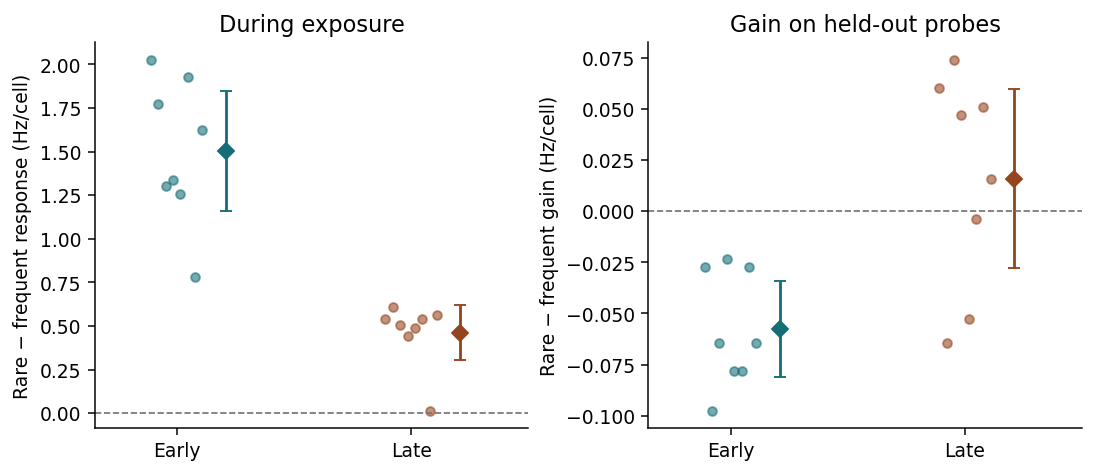

In [8]:
fig, axes = plt.subplots(1,2,figsize=(8,3.4),layout="constrained")
for ax,(label,values) in zip(axes,[("During exposure",acute),("Gain on held-out probes",probe)]):
    for i,(age,color) in enumerate([("early","#146d77"),("late","#94451d")]):
        v = values.loc[age].to_numpy() if ax is axes[0] else values["nominal",age]
        mean, lo, hi = summary(v)
        ax.scatter(i+np.linspace(-.11,.11,len(v)),v,color=color,alpha=.58,s=22)
        ax.errorbar(i+.21,mean,yerr=[[mean-lo],[hi-mean]],color=color,fmt="D",capsize=3)
    ax.axhline(0,color="0.45",lw=.9,ls="--")
    ax.set(xticks=[0,1],xticklabels=["Early","Late"],xlim=(-.35,1.5),title=label)
    ax.spines[["top","right"]].set_visible(False)
axes[0].set_ylabel("Rare − frequent response (Hz/cell)")
axes[1].set_ylabel("Rare − frequent gain (Hz/cell)")
show_plot(fig)

Dots represent the eight seeds. Diamonds and bars show the mean and pointwise 95% interval. The panels use different vertical scales. All eight early seeds showed an acute rare-tone advantage and a retained frequent-tone advantage. The latter persisted on the finer grid. The late 100-tone baseline probe contrast remained imprecise on both grids.

An independent 32-seed cohort tested acute firing and direct efficacy. Its small positive late efficacy contrast concerns synaptic change. These extra seeds did not contribute functional probes.

In [9]:
replication = read("stage2/replication_checks.csv").query("dt_ms==0.5 and condition=='intact' and regime in ['early','late']")
display(replication[["regime","metric","n","mean","lo","hi"]].set_index(["regime","metric"]).round(5))

n     mean       lo       hi
regime metric                                               
early  response_dev_minus_std  32  1.44097  1.29884  1.58310
       efficacy_dev_minus_std  32 -0.01362 -0.01487 -0.01237
       input_dev_minus_std     32 -0.01076 -0.37699  0.35547
late   response_dev_minus_std  32  0.37786  0.28876  0.46697
       efficacy_dev_minus_std  32  0.00265  0.00132  0.00399
       input_dev_minus_std     32 -0.01076 -0.37699  0.35547

## 6. What changes between 100 and 1,000 presentations?

The 1,000-token protocol uses four seeds. Generating a separate 100-token stream with the same seed produces a different early sequence. To isolate continued learning, compare the first 100 tokens of the long stream with its own endpoint. Both tests use the same pretraining probe reference.

In [10]:
horizons = read("stage5/horizon_seeds.csv")
long = horizons.pivot(index=["age","seed"],columns="comparison",values="gain_hz_D_minus_S")
shift = long.long_1000-long.long_prefix_100
np.testing.assert_allclose(shift,long.long_minus_own_prefix,atol=1e-12)
reference = read("stage5/horizon_estimates.csv").query("metric=='gain_hz_D_minus_S'").set_index(["age","comparison"])
keys = {"First 100":"long_prefix_100","All 1,000":"long_1000","Paired change":"long_minus_own_prefix"}
rows = []
for age in ("early","late"):
    for label, series in [("First 100",long.long_prefix_100),("All 1,000",long.long_1000),("Paired change",shift)]:
        vals = series.loc[age]
        est = summary(vals)
        np.testing.assert_allclose(est,reference.loc[(age,keys[label]),["mean","lo","hi"]].to_numpy(dtype=float),atol=1e-12)
        rows.append((label,age,len(vals),*est))
show_intervals(rows,"Hz/cell")

,,Seeds,Mean (Hz/cell),95% lower,95% upper
Measurement,Regime,,,,
First 100,early,4,-0.05273,-0.07050,-0.03497
"All 1,000",early,4,-0.17969,-0.26689,-0.09248
Paired change,early,4,-0.12695,-0.20651,-0.04739
First 100,late,4,0.03809,-0.03267,0.10884
"All 1,000",late,4,-0.09521,-0.19836,0.00794
Paired change,late,4,-0.13330,-0.22679,-0.03981


Between these two endpoints the rare-minus-frequent gain fell by 0.127 Hz/cell early and 0.133 Hz/cell late. The late paired change had an interval below zero even though the late endpoint interval included zero. These statistics answer different questions. Direct efficacies stayed between 0.392 and 0.685 throughout the long baseline runs. Balancing the tone counts moved the early efficacy contrast from −0.0459 to +0.0041. That control changes both tone count and spacing.

## 7. Can the subplate relay store an early rare-tone advantage?

Stage 6 added STDP to existing excitatory SP→L4 contacts while direct contacts continued to learn. Each relay efficacy starts at 0.5 and scales original conductance by twice its current value. Pre-events occur at SP spike arrival after the 1 ms delay. The nominal timing amplitudes were transferred from the direct rule as a modeling assumption. The selective-reset test restores only the relay efficacies at test and keeps the alternative model's learned direct weights.

In [11]:
relay = read("stage6/seed_results.csv")
np.testing.assert_allclose(relay.alternative_contrast-relay.baseline_contrast,relay.paired_contrast,atol=1e-12)
reference = read("stage6/estimates.csv").set_index(["age","metric"])
rows = []
for age, group in relay.groupby("age"):
    for label, field in [("Fixed relay","baseline_contrast"),("Plastic relay","alternative_contrast"),
                         ("Relay reset at test","reset_relay_contrast"),("Plastic − fixed","paired_contrast")]:
        est = summary(group[field])
        np.testing.assert_allclose(est,reference.loc[(age,field),["mean","lo","hi"]].to_numpy(dtype=float),atol=1e-12)
        rows.append((label,age,len(group),*est))
show_intervals(rows,"Hz/cell")

,,Seeds,Mean (Hz/cell),95% lower,95% upper
Measurement,Regime,,,,
Fixed relay,early,8,-0.05762,-0.08113,-0.03410
Plastic relay,early,8,-0.29639,-0.36201,-0.23076
Relay reset at test,early,8,-0.05933,-0.08331,-0.03535
Plastic − fixed,early,8,-0.23877,-0.28937,-0.18817
Fixed relay,late,8,0.01587,-0.02784,0.05957
Plastic relay,late,8,0.17798,0.12711,0.22885
Relay reset at test,late,8,0.02417,-0.01987,0.06821
Plastic − fixed,late,8,0.16211,0.13598,0.18824


All eight early seeds moved farther toward the frequent tone with a plastic relay. The late contrast moved toward the rare tone because both responses declined and the frequent tone lost more. Resetting the relay at test brought the contrasts close to baseline. This locates most of the measured shift in the expression of the learned relay weights. The proposed early reversal failed for the specified rule.

## 8. What numerical accuracy supports these conclusions?

Stage 1 tested passive membrane decay, signed conductance effects, release conservation, refractory and delay timing, STDP pairing, weight bounds, frozen weights, silence and terminal-boundary events. A nonbinary-step input-binning error was corrected. All 20 regression tests passed after correction. The nominal and fine-grid functional results above check the early sign directly. A separate eight-impulse challenge tests whether a single near-threshold spike survives refinement.

In [12]:
spikes = read("stage1/threshold_spikes.csv").query("impulses==8 and spike==4").copy()
chosen = spikes[spikes.step_ms.isin([.5,.125,.0625,.03125,.0078125,.0009765625])]
display(chosen[["step_ms","native_count","reference_count","quadrature_reference_ms","native_ms"]]
        .rename(columns={"step_ms":"Step (ms)","native_count":"Grid spikes","reference_count":"Reference spikes",
                         "quadrature_reference_ms":"Reference 4th spike (ms)","native_ms":"Grid 4th spike (ms)"})
        .set_index("Step (ms)").fillna("Absent"))
assert len(chosen)==6 and chosen.native_count.tolist()==[3,3,3,4,4,4]

,Grid spikes,Reference spikes,Reference 4th spike (ms),Grid 4th spike (ms)
Step (ms),,,,
0.50000,3,4,16.3629,Absent
0.12500,3,4,16.3629,Absent
0.06250,3,4,16.3629,Absent
0.03125,4,4,16.3629,17.6875
0.00781,4,4,16.3629,16.48438
0.00098,4,4,16.3629,16.40039


The continuous reference has four spikes. The native solver misses the fourth even at 0.125 ms, first recovers it at 0.03125 ms, and still records it late there. A delayed third spike also delays the end of its refractory period, allowing enough conductance decay to suppress the next crossing. Agreement in a population contrast therefore gives limited information about any one near-threshold event.

## Interpretation and reproduction

**What the model explains.** Frequency-dependent resource recovery can produce acute context selectivity. In the early regime, accumulated timing-dependent updates nevertheless favor the frequent tone in both direct efficacy and held-out firing. Giving the relay the same plasticity rule amplifies this preference.

**What remains open.** These are immediate within-regime probes. The model has no intervening maturation, biological delay to testing, or adult cortical-map measurement. Connectivity gains, resource time constants and relay learning parameters are assumptions. The small late endpoint in the four-seed long exposure needs greater precision. The 32-seed efficacy replication cannot settle that functional question.

**Reproduction.** The accompanying stage reports specify commands, raw measurements, tested seeds, numerical settings and limits of verification. From the extracted root, run `python -B stage7/execute.py` to clear outputs, execute the notebook in a fresh kernel and validate its outputs. The full exposure studies can be regenerated separately.

| Experiment | Evidence and commands |
|---|---|
| Solver tests, grid comparisons, isolated threshold crossings | [Numerical verification](../stage1/VALIDATION.md) |
| Acute response, direct weights, additional seeds | [Primary comparisons](../stage2/VERIFICATION.md) |
| Matched histories and selective depression | [Context experiment](../stage3/MECHANISM.md) |
| Functional probes on two grids | [Held-out readout](../stage4/RETENTION.md) |
| Extended exposure, balanced counts and connectivity controls | [Long exposure](../stage5/LONG_EXPOSURE.md) |
| Relay plasticity and selective reset | [Alternative model](../stage6/RELAY_EXPERIMENT.md) |